In [1]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, root_mean_squared_error,mean_absolute_error,r2_score
from sklearn import tree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.discriminant_analysis import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from collections import defaultdict
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
import math
import statistics
from sklearn.ensemble import RandomForestRegressor
import random
from sklearn.model_selection import TimeSeriesSplit
from numpy import random
import json
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
import mpld3


#### 1. **Data Preprocessing**

In [2]:
train = pd.read_csv(
    'train.csv',
    delimiter=',',
    dtype={
        'building_id': 'int32',
        'meter': 'int8'
    },
    parse_dates=['timestamp']
)


train = train[train.meter == 0]

train = train.drop('meter', axis=1)

building_set = train['building_id'].unique()

meta = pd.read_csv(
    'building_metadata.csv',
    delimiter=',',
    dtype={
        'building_id': 'int32',
        'site_id': 'int8',  
    }
)
meta['floor_missing'] = meta['floor_count'].isna().astype('int8')
meta['year_missing'] = meta['year_built'].isna().astype('int8')

meta['year_built'] = meta['year_built'].fillna(meta['year_built'].median())
meta['year_built'] = meta['year_built'].astype('int16')

meta['floor_count'] = meta['floor_count'].fillna(meta['floor_count'].median())
meta['floor_count'] = meta['floor_count'].astype('int16')

meta = pd.get_dummies(meta, columns=['primary_use'], drop_first=False)

meta = meta[meta['building_id'].isin(building_set)]


site_ids = meta['site_id'].unique()

weather = pd.read_csv(
    'weather_train.csv',
    delimiter=',',
    dtype={
        'site_id': 'int8'
    },
    parse_dates=['timestamp']
)

weather = weather[weather['site_id'].isin(site_ids)]

train_meta = pd.merge(train, meta, on='building_id', how='left')
full_df = pd.merge(train_meta, weather, on=['site_id','timestamp'], how='left')

full_df.head(80)

,building_id,timestamp,meter_reading,site_id,square_feet,year_built,floor_count,floor_missing,year_missing,primary_use_Education,...,primary_use_Technology/science,primary_use_Utility,primary_use_Warehouse/storage,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed
0,0,2016-01-01,0.0,0,7432,2008,3,1,0,True,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
1,1,2016-01-01,0.0,0,2720,2004,3,1,0,True,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
2,2,2016-01-01,0.0,0,5376,1991,3,1,0,True,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
3,3,2016-01-01,0.0,0,23685,2002,3,1,0,True,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
4,4,2016-01-01,0.0,0,116607,1975,3,1,0,True,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,77,2016-01-01,0.0,0,24456,1968,3,1,0,False,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
76,78,2016-01-01,0.0,0,76257,2007,3,1,0,True,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
77,79,2016-01-01,0.0,0,36240,2010,3,1,0,False,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
78,80,2016-01-01,0.0,0,156111,2001,3,1,0,False,...,False,False,False,25.0,6.0,20.0,NaN,1019.7,0.0,0.0


In [3]:
buildings = full_df['building_id'].unique()
per_building = {}

weather_cols = ["air_temperature", "cloud_coverage", "dew_temperature", "precip_depth_1_hr","sea_level_pressure", "wind_direction","wind_speed"]

for b in buildings:
    df_b = full_df[full_df['building_id'] == b].set_index('timestamp').sort_index()
    
    df_b['hour'] = df_b.index.hour
    df_b['dayofweek'] = df_b.index.dayofweek
    df_b['month'] = df_b.index.month
    df_b['day'] = df_b.index.day
    df_b['is_weekend'] = (df_b.index.dayofweek >= 5).astype(int)
    df_b['is_business_hour'] = df_b['hour'].between(8, 18).astype(int)

    df_b = df_b.resample('h').asfreq()
    
    primary_use_cols = [c for c in df_b.columns if 'primary_use' in c]
    for col in primary_use_cols:
        df_b[col] = df_b[col].ffill().bfill().astype(bool)
    
    df_b['meter_reading'] = df_b['meter_reading'].ffill(limit=24)
    df_b = df_b.dropna(subset=['meter_reading'])

    cols = [c for c in weather_cols if c in df_b.columns]
    df_b[cols] = df_b[cols].interpolate(limit=6).ffill().bfill()

    df_b['load_lag_1h'] = df_b['meter_reading'].shift(1)
    df_b['load_lag_24h'] = df_b['meter_reading'].shift(24)
    df_b['load_lag_168h'] = df_b['meter_reading'].shift(168)

    df_b['load_roll_24h_mean'] = df_b['meter_reading'].shift(1).rolling(24).mean()
    df_b['load_roll_24h_std'] = df_b['meter_reading'].shift(1).rolling(24).std()
    df_b['load_roll_168h_std'] = df_b['meter_reading'].shift(1).rolling(168).std()
    df_b['load_roll_168h_mean'] = df_b['meter_reading'].shift(1).rolling(168).mean()

    df_b['hour_x_temp'] = df_b['hour'] * df_b['air_temperature']
    df_b['hour_sin'] = np.sin(2 * np.pi * df_b['hour'] / 24)
    df_b['hour_cos'] = np.cos(2 * np.pi * df_b['hour'] / 24)
    df_b = df_b.dropna()
    per_building[b] = df_b


/tmp/ipykernel_1480/1922050794.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_b[col] = df_b[col].ffill().bfill().astype(bool)
/tmp/ipykernel_1480/1922050794.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_b[col] = df_b[col].ffill().bfill().astype(bool)
/tmp/ipykernel_1480/1922050794.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasti

In [4]:
building_type = defaultdict(set)
for b, df_b in per_building.items():
    df_b = df_b.filter(regex='primary_use').head(1)
    for i, row in df_b.iterrows():
        for r,v in row.items():
            if v == True:
                building_type[r].add(b)

acf24_per_type = defaultdict(list)
for b_type, buildingSet in building_type.items():
    for b in buildingSet:
        s = per_building[b]['meter_reading'].dropna()
        if len(s) < 48:
            continue
        a = acf(s, nlags=24, fft=True)[24]
        acf24_per_type[b_type].append((b, a))

median_buildings = {}
for b_type, vals in acf24_per_type.items():
    acfs = np.array([a for _, a in vals])
    med = np.median(acfs)

    b_med, a_med = min(vals, key=lambda x: abs(x[1] - med))
    median_buildings[b_type] = (b_med, a_med)

median_buildings = dict(sorted(median_buildings.items(), key=lambda item: item[1][1]))

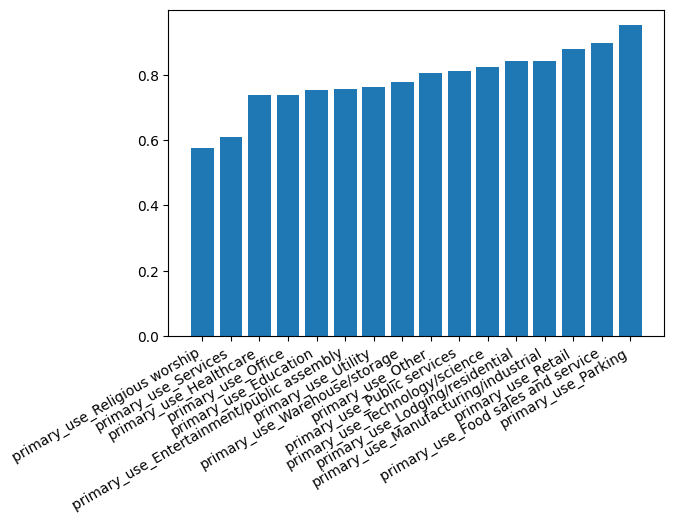

In [5]:
categories = list(median_buildings.keys())
values = [acf_value for b,acf_value in median_buildings.values()]


fig, ax = plt.subplots()
ax.bar(range(len(median_buildings)), values, tick_label=categories, align='center')

fig.autofmt_xdate()
plt.show()


In [9]:
import heapq
def quality_check(build_id, freq="h"):
    df = per_building[build_id]
    idx = pd.DatetimeIndex(pd.to_datetime(df.index)).sort_values()
    u = idx.unique()
    start, end = u.min(),u.max()
    duration_days = (end - start) / pd.Timedelta(days=1)

    expected = pd.date_range(start=start, end=end, freq=freq)
    expected_n = len(expected)
    actual_n = len(u)

    missing_ratio = (1 - (actual_n / expected_n))

    max_gap = pd.Timedelta(0)
    if actual_n >= 2:
        max_gap = (u[1:] - u[:-1]).max()
    
    return {
        "max_gap" : max_gap,
        "missing_ratio" : missing_ratio,
        "duration_days" : duration_days
    }


def filter_buildings(build_dict, max_gap_th = pd.Timedelta(days=7), miss_ratio_th = 0.1, days_th_min = 310, k =3):
    res = []
    for c,b in build_dict.items():
        dict_res = quality_check(b)
        max_gap = dict_res['max_gap']
        miss_ratio = dict_res['missing_ratio']
        duration_days = dict_res['duration_days']
        if max_gap < max_gap_th and miss_ratio < miss_ratio_th and duration_days >= days_th_min:
            key = (miss_ratio, max_gap, -duration_days)
            heapq.heappush(res, (key, c, b))
    return heapq.nsmallest(k, res)


In [11]:

median = statistics.median(values)
eta = 0.01
which = [index for index,value in enumerate(values) if value>=median-eta and value <= median+eta]
if not which:
    which = min(enumerate(values), key=lambda x: abs(x[1] - median))[0]
else:
    which = min(range(len(values)), key=lambda i: abs(values[i] - median))[0]

nr_buildings = 3
chosen_category_buildings = {}
final_buildings = []
diameter = 0
while len(final_buildings) < nr_buildings and diameter < len(categories):
    diameter += 1
    lo = max(0,which-diameter)
    hi = min(len(categories)-1, which+diameter)

    for i in range(lo,hi+1):
        chosen_category_buildings[categories[i]] = median_buildings[categories[i]][0]
        
    final_buildings = filter_buildings(chosen_category_buildings, k=nr_buildings)

final_buildings = {c:b for (_,c,b) in final_buildings}
print(final_buildings)

{'primary_use_Entertainment/public assembly': np.int32(1317), 'primary_use_Public services': np.int32(432), 'primary_use_Warehouse/storage': np.int32(425)}


In [9]:
#DID NOT DO YET, AT THE END WHEN COMPARING
def calculate_cv(build_id):
    data = per_building[build_id]['meter_reading']
    cv = (np.std(data) / (np.mean(data) + 1e-9)) * 100 
    return cv

def weekend_week_ratio(build_id):
    y = per_building[build_id]['meter_reading']
    tmp = y.to_frame("y")
    tmp["dow"] = tmp.index.dayofweek
    week_mean = tmp[tmp["dow"] < 5]["y"].mean()
    weekend_mean = tmp[tmp["dow"] >= 5]["y"].mean()
    ratio = (weekend_mean/(week_mean+ 1e-9))
    return ratio

def season_amplitude(build_id):
    df = per_building[build_id]['meter_reading']
    m = df.groupby(df.index.month).mean()
    winter = m[[12,1,2]].mean()
    summer = m[[6,7,8]].mean()
    season_amp_norm = (winter - summer) / df.mean()
    return season_amp_norm


for _,b in final_buildings.items():
    print(calculate_cv(b))
    print(weekend_week_ratio(b))
    print(season_amplitude(b))

26.02974916484337
0.9602069480638421
0.013145770190021886
43.025487445002774
0.7533699553798555
-0.6361241135316561
28.735246063961316
0.8199271222812332
-0.14349699200124097


In [12]:
# two_fold_selection
def train_val_test(build_id):
    data = per_building[build_id]
    data = data.sort_index()
    minDate, maxDate = data.index.min(), data.index.max()
    start = minDate + pd.DateOffset(months=8)
    splits = []
    for val_start in pd.date_range(start=start, end=maxDate, freq='MS'):
        train_end = val_start - pd.Timedelta(hours=1)
        valid_end = (val_start+pd.offsets.MonthEnd()) + pd.Timedelta(hours=23)
        if valid_end > maxDate:
            break
        splits.append((train_end,val_start,valid_end))
    return [splits[1],splits[-1]]

# train_test_data
dataset_b = {}
for _,b in final_buildings.items():
    intervals = train_val_test(b)
    dataset_b[b] = {}
    for idx, (train_end, val_start, val_end) in enumerate(intervals):
        data = per_building[b]
        train_data = data[:train_end]
        val_data = data[val_start:val_end]
        dataset_b[b]["autumn" if idx == 0 else "winter"] = {
            'train': train_data,
            'val': val_data
        }

In [11]:
print(train_val_test(504))

[(Timestamp('2016-10-31 23:00:00'), Timestamp('2016-11-01 00:00:00'), Timestamp('2016-11-30 23:00:00')), (Timestamp('2016-11-30 23:00:00'), Timestamp('2016-12-01 00:00:00'), Timestamp('2016-12-31 23:00:00'))]


In [13]:
from functools import reduce

def get_season_mask(dataframe, season):
    idx = dataframe.index
    if season == "autumn":
        return idx.month.isin([9,10,11])
    if season == "winter":
        return idx.month.isin([1,2,12])
    else:
        raise ValueError(f"Unknown season : {season}")
    

def get_metrics(pred,test):
    rmse = root_mean_squared_error(test, pred)
    mae = mean_absolute_error(test, pred)
    nmae = (mae / (test.mean() + 1e-9))
    r_2 = r2_score(test,pred)
    return {"rmse": rmse, "mae": mae, "nmae":nmae, "r_2": r_2}

def df_and_test(build_id):
    y = per_building[build_id]["meter_reading"].sort_index()
    all_test = []
    for key in dataset_b[build_id]:
        test_data = dataset_b[build_id][key]['val']['meter_reading']
        all_test.append(test_data)
    y_test = pd.concat(all_test).sort_index()
    return (y,y_test)


def baseline_persistance_model(build_id, season):
    y,y_test = df_and_test(build_id)
    y_hat = y.shift(24).loc[y_test.index]

    m = get_season_mask(y_test, season)
    y_hat, y_test = y_hat[m], y_test[m]
    return y_hat, y_test


def baseline_mean_model(build_id, season):
    y,y_test = df_and_test(build_id)
    dataframes = [y.shift(i).loc[y_test.index] for i in range(24,169,24)]
    print(dataframes)
    y_hat_test = (reduce(lambda x, y: x + y, dataframes))/7

    m = get_season_mask(y_test, season)
    y_hat_test, y_test = y_hat_test[m], y_test[m]
    return y_hat_test, y_test

In [15]:
baseline_persistance_model(425, "winter")

(timestamp
 2016-12-01 00:00:00    112.86
 2016-12-01 01:00:00    109.84
 2016-12-01 02:00:00    107.38
 2016-12-01 03:00:00    104.66
 2016-12-01 04:00:00    105.76
                         ...  
 2016-12-31 19:00:00     41.03
 2016-12-31 20:00:00     40.66
 2016-12-31 21:00:00     40.37
 2016-12-31 22:00:00     40.96
 2016-12-31 23:00:00     40.81
 Name: meter_reading, Length: 744, dtype: float64,
 timestamp
 2016-12-01 00:00:00    109.94
 2016-12-01 01:00:00    109.47
 2016-12-01 02:00:00    108.63
 2016-12-01 03:00:00    107.49
 2016-12-01 04:00:00    109.07
                         ...  
 2016-12-31 19:00:00     30.36
 2016-12-31 20:00:00     30.97
 2016-12-31 21:00:00     31.63
 2016-12-31 22:00:00     32.20
 2016-12-31 23:00:00     32.68
 Name: meter_reading, Length: 744, dtype: float64)

#### 2. **Global Models**

##### Random Forest Model

In [16]:
def get_correlated_columns(build_id):
    data = pd.Series(dataset_b[build_id]['autumn']['train'].columns).to_frame("y")
    print(data)
    primary_uses_cols = data[data['y'].str.contains('primary_use')]['y'].tolist()
    weather_cols = data.iloc[24:31]['y'].tolist()
    time_cols = data.iloc[31:37]['y'].tolist()
    lag_columns = data[data['y'].str.contains('load')]['y'].tolist()
    nonlin_columns = data[data['y'].str.contains('hour_')]['y'].tolist()
    return {
        "usage": primary_uses_cols,
        "weather": weather_cols,
        "time": time_cols,
        "lag": lag_columns,
        "nonlinear": nonlin_columns
    }   

In [17]:
get_correlated_columns(432)

                                            y
0                                 building_id
1                               meter_reading
2                                     site_id
3                                 square_feet
4                                  year_built
5                                 floor_count
6                               floor_missing
7                                year_missing
8                       primary_use_Education
9   primary_use_Entertainment/public assembly
10         primary_use_Food sales and service
11                     primary_use_Healthcare
12            primary_use_Lodging/residential
13       primary_use_Manufacturing/industrial
14                         primary_use_Office
15                          primary_use_Other
16                        primary_use_Parking
17                primary_use_Public services
18              primary_use_Religious worship
19                         primary_use_Retail
20                       primary_u

{'usage': ['primary_use_Education',
  'primary_use_Entertainment/public assembly',
  'primary_use_Food sales and service',
  'primary_use_Healthcare',
  'primary_use_Lodging/residential',
  'primary_use_Manufacturing/industrial',
  'primary_use_Office',
  'primary_use_Other',
  'primary_use_Parking',
  'primary_use_Public services',
  'primary_use_Religious worship',
  'primary_use_Retail',
  'primary_use_Services',
  'primary_use_Technology/science',
  'primary_use_Utility',
  'primary_use_Warehouse/storage'],
 'weather': ['air_temperature',
  'cloud_coverage',
  'dew_temperature',
  'precip_depth_1_hr',
  'sea_level_pressure',
  'wind_direction',
  'wind_speed'],
 'time': ['hour',
  'dayofweek',
  'month',
  'day',
  'is_weekend',
  'is_business_hour'],
 'lag': ['load_lag_1h',
  'load_lag_24h',
  'load_lag_168h',
  'load_roll_24h_mean',
  'load_roll_24h_std',
  'load_roll_168h_std',
  'load_roll_168h_mean'],
 'nonlinear': ['hour_x_temp', 'hour_sin', 'hour_cos']}

In [37]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# param_grid = {
#     'min_samples_leaf' : [10,15],
#     'n_estimators': [100, 200],
#     'max_depth': [None, 10, 20],
# }

param_grid = {
    'min_samples_leaf' : [10],
    'n_estimators': [100],
    'max_depth': [None],
}

def train_test_fn(build_id,fold_key, seasonal = False, is_svm = False):

    train_data = dataset_b[build_id][fold_key]['train']
    test_data = dataset_b[build_id][fold_key]['val']
    if seasonal:
        train_mask = get_season_mask(train_data, fold_key)
        train_data= train_data[train_mask]

    X_train = train_data.drop('meter_reading', axis=1)
    y_train = train_data['meter_reading']

    X_test = test_data.drop('meter_reading', axis=1)
    y_test = test_data['meter_reading']

    if is_svm:
        scaler = StandardScaler().fit(X_train)
        X_train_scaled = scaler.transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        X_train = pd.DataFrame(X_train_scaled, index=X_train.index, columns=X_train.columns)
        X_test = pd.DataFrame(X_test_scaled, index=X_test.index, columns=X_test.columns)

    return (X_train,y_train,X_test,y_test)

def rf_predict(X_train, y_train, X_test, y_test):
    tscv = TimeSeriesSplit(n_splits=3)
    grid_rf = GridSearchCV(RandomForestRegressor(
        random_state=SEED,
    ),param_grid, cv=tscv, return_train_score=False, n_jobs=4)

    grid_rf.fit(X_train, y_train)
    y_pred = pd.Series(grid_rf.predict(X_test), index=y_test.index)
    return y_pred, grid_rf


def permutation_importance(build_id,fold_key, iterations = 10,seasonal = False, predict_func = rf_predict, is_svm = False):
    X_train, y_train, X_test, y_test = train_test_fn(build_id,fold_key,seasonal, is_svm=is_svm)
    y_pred,grid_rf = predict_func(X_train, y_train, X_test, y_test)
    
    res = {}
    columns = get_correlated_columns(build_id)
    for key in columns:
        group_cols = columns[key]
        maes = []
        for r in range(iterations):
            rng = np.random.RandomState(SEED + r)
            X_test_new = X_test.copy()
            perm_idx = rng.permutation(len(X_test_new))

            X_test_new[group_cols] = X_test_new[group_cols].iloc[perm_idx].to_numpy()
            y_perm = grid_rf.predict(X_test_new)
            mae_permuted = mean_absolute_error(y_test, y_perm)
            maes.append(mae_permuted)

        mae_permuted = np.mean(maes)
        mae_std = np.std(maes)
        mae_original = mean_absolute_error(y_test,y_pred)
        res[key] = {
            "mae_permuted": mae_permuted,
            "mae_std": mae_std,
            "mae_original": mae_original,
            "mae_rel_increase": (mae_permuted - mae_original) / mae_original
        }
    return res

def feature_importance(build_id,fold_key,seasonal = False, predict_func = rf_predict):
    X_train, y_train, X_test, y_test = train_test_fn(build_id,fold_key,seasonal)
    _,grid_rf = predict_func(X_train, y_train, X_test, y_test)
    model = grid_rf.best_estimator_
    mdi = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    return mdi


def random_forrest(build_id,season,seasonal = False):
    X_train, y_train, X_test, y_test = train_test_fn(build_id,season,seasonal)
    y_pred, _ = rf_predict(X_train, y_train, X_test, y_test)
    return (y_pred, y_test)

In [14]:
global_rf_data = {}
seasonList = ["autumn", "winter"]
for b in dataset_b:
    global_rf_data[b] = {
        "metrics": { 
            season: get_metrics(*random_forrest(b,season)) for season in seasonList
        },
        "p_importance" : {
            season: permutation_importance(b,season) for season in seasonList
        },
        "f_importance" : {
            season: feature_importance(b,season) for season in seasonList
        }
    }

In [35]:
for b in dataset_b:
    print(global_rf_data[b]["metrics"])

{'autumn': {'rmse': 38.43831450867664, 'mae': 25.46630450475436, 'nmae': np.float64(0.06433618361151368), 'r_2': 0.6934338732635612}, 'winter': {'rmse': 34.19346189794577, 'mae': 17.003922505927704, 'nmae': np.float64(0.044837800219919836), 'r_2': 0.7832535884108847}}
{'autumn': {'rmse': 54.0975558900152, 'mae': 34.44513600962811, 'nmae': np.float64(0.14735873911035555), 'r_2': 0.7821123003094403}, 'winter': {'rmse': 27.54073322403016, 'mae': 15.321738488950633, 'nmae': np.float64(0.08800464995588174), 'r_2': 0.9542160384791979}}
{'autumn': {'rmse': 7.510751555164197, 'mae': 4.924401213734342, 'nmae': np.float64(0.03393070993172923), 'r_2': 0.9337719233811895}, 'winter': {'rmse': 23.580847878121652, 'mae': 11.640130468184434, 'nmae': np.float64(0.08518685041560153), 'r_2': 0.7986082196438907}}


##### XGBoost

In [16]:
xg_param_grid = {
    'n_estimators': [100, 500, 1000],
    'max_depth': [3, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
}


def xg_predict(X_train, y_train, X_test, y_test):
    tscv = TimeSeriesSplit(n_splits=3)
    grid_xg = GridSearchCV(XGBRegressor(
        random_state=SEED,
    ),xg_param_grid, cv=tscv, return_train_score=False, n_jobs=4)

    grid_xg.fit(X_train, y_train)
    y_pred = pd.Series(grid_xg.predict(X_test), index=y_test.index)
    return y_pred, grid_xg

def xg_boost(build_id,season,seasonal = False):
    X_train, y_train, X_test, y_test = train_test_fn(build_id,season,seasonal)
    y_pred, _ = xg_predict(X_train, y_train, X_test, y_test)
    return (y_pred, y_test)

In [17]:
global_xg_data = {}
seasonList = ["autumn", "winter"]
for b in dataset_b:
    global_xg_data[b] = {
        "metrics": { 
            season: get_metrics(*xg_boost(b,season)) for season in seasonList
        },
        "p_importance" : {
            season: permutation_importance(b,season,predict_func=xg_predict) for season in seasonList
        },
        "f_importance" : {
            season: feature_importance(b,season,predict_func=xg_predict) for season in seasonList
        }
    }

In [18]:
for b in dataset_b:
    print(global_xg_data[b]["metrics"])

{'autumn': {'rmse': 55.40867848471169, 'mae': 32.25570306769477, 'nmae': np.float64(0.08148841677025619), 'r_2': 0.3629829163906769}, 'winter': {'rmse': 47.41176303561375, 'mae': 24.031036140359863, 'nmae': np.float64(0.06336766103018314), 'r_2': 0.5832861063349034}}
{'autumn': {'rmse': 65.86884134453375, 'mae': 40.08561194917257, 'nmae': np.float64(0.17148909592477604), 'r_2': 0.6769740044513528}, 'winter': {'rmse': 45.12811088222695, 'mae': 29.543975676259688, 'nmae': np.float64(0.16969400956486302), 'r_2': 0.877070340498159}}
{'autumn': {'rmse': 7.6206268767530405, 'mae': 5.1104943559033815, 'nmae': np.float64(0.035212951599936725), 'r_2': 0.9318200393906247}, 'winter': {'rmse': 26.122815603542804, 'mae': 12.712953943642235, 'nmae': np.float64(0.0930381758948102), 'r_2': 0.752848712277507}}


##### SVR

In [ ]:
from sklearn.svm import SVR

def svr_predict(X_train, y_train, X_test, y_test, custom_grid=None):
    tscv = TimeSeriesSplit(n_splits=3)
    
    if custom_grid is None:
        train_std = np.std(y_train)
        custom_grid = {"epsilon": [0.1 * train_std],
                       "C": [10 * train_std],
                       "kernel": ['rbf']}
    
    grid_svr = GridSearchCV(SVR(), custom_grid, cv=tscv, return_train_score=False, n_jobs=4)

    grid_svr.fit(X_train, y_train)
    y_pred = pd.Series(grid_svr.predict(X_test), index=y_test.index)
    return y_pred, grid_svr

def svr(build_id, season, seasonal=False):
    X_train, y_train, X_test, y_test = train_test_fn(build_id, season, seasonal, is_svm=True)

    train_std = np.std(y_train)
    svr_param_grid = {"epsilon": [0.05 * train_std, 0.1 * train_std, 0.2 * train_std],
                      "C": [1 * train_std, 10 * train_std, 100 * train_std],
                      "kernel": ['rbf', 'poly']}
    y_pred, _ = svr_predict(X_train, y_train, X_test, y_test, custom_grid=svr_param_grid)
    return (y_pred, y_test)

In [33]:
global_svr_data = {}
seasonList = ["autumn", "winter"]
for b in dataset_b:
    global_svr_data[b] = {
        "metrics": { 
            season: get_metrics(*svr(b,season)) for season in seasonList
        },
        "p_importance" : {
            season: permutation_importance(b,season,predict_func=svr_predict, is_svm=True) for season in seasonList
        }
    }

In [34]:
for b in dataset_b:
    print(global_svr_data[b]["metrics"])

{'autumn': {'rmse': 31.9295264163684, 'mae': 20.161105440125027, 'nmae': np.float64(0.050933522025734625), 'r_2': 0.7884658697588875}, 'winter': {'rmse': 36.91833726673915, 'mae': 20.24254821213108, 'nmae': np.float64(0.05337776224051957), 'r_2': 0.7473321201259002}}
{'autumn': {'rmse': 73.98919474854692, 'mae': 48.48846514770195, 'nmae': np.float64(0.20743709891476558), 'r_2': 0.5924189095345813}, 'winter': {'rmse': 50.68315835309977, 'mae': 38.64688607590323, 'nmae': np.float64(0.2219790974403742), 'r_2': 0.844943594544423}}
{'autumn': {'rmse': 10.370661766622641, 'mae': 7.706490352998564, 'nmae': np.float64(0.053100199884194565), 'r_2': 0.8737334570115054}, 'winter': {'rmse': 36.456210312146695, 'mae': 17.83294077962151, 'nmae': np.float64(0.13050816421826966), 'r_2': 0.5186444873079897}}


#### 3. **Seasonal Models**

##### Seasonal Naive Persistance Model & 7-Day hourly mean model

In [19]:
seasonList = ["autumn", "winter"]
seasonal_naive_metrics, seasonal_mean_metrics = {}, {}

for b in dataset_b:
    seasonal_naive_metrics[b], seasonal_mean_metrics[b] = {}, {}
    for season in seasonList:
        naive_pred, naive_test = baseline_persistance_model(b, season)
        mean_pred, mean_test = baseline_mean_model(b, season)
        seasonal_naive_metrics[b][season] = get_metrics(naive_pred, naive_test)
        seasonal_mean_metrics[b][season] = get_metrics(mean_pred, mean_test)
print(seasonal_naive_metrics)
print(seasonal_mean_metrics)

{np.int32(1317): {'autumn': {'rmse': 48.29370009479325, 'mae': 30.63333194444445, 'nmae': np.float64(0.07738977864818536), 'r_2': 0.5160767851814507}, 'winter': {'rmse': 61.708138989159096, 'mae': 29.104841397849462, 'nmae': np.float64(0.07674682495020158), 'r_2': 0.29408783145778816}}, np.int32(432): {'autumn': {'rmse': 87.20485807514065, 'mae': 51.436509040333796, 'nmae': np.float64(0.22004904014033613), 'r_2': 0.43381444560524796}, 'winter': {'rmse': 94.89492348217671, 'mae': 46.42981182795699, 'nmae': np.float64(0.2666824877858009), 'r_2': 0.45643894741034197}}, np.int32(425): {'autumn': {'rmse': 27.118923897892664, 'mae': 17.91513212795549, 'nmae': np.float64(0.12344102871367986), 'r_2': 0.13658367757899192}, 'winter': {'rmse': 45.70007764663647, 'mae': 22.182056451612905, 'nmae': np.float64(0.16233662758495784), 'r_2': 0.24359083231087975}}}
{np.int32(1317): {'autumn': {'rmse': 42.561622277598104, 'mae': 30.700806150793653, 'nmae': np.float64(0.07756024048052201), 'r_2': 0.624135

##### Seasonal Random Forest

In [20]:
seasonal_rf_data = {}
seasonList = ["autumn", "winter"]
for b in dataset_b:
    seasonal_rf_data[b] = {
        "metrics": { 
            season: get_metrics(*random_forrest(b,season,True)) for season in seasonList
        },
        "p_importance" : {
            season: permutation_importance(b,season,True) for season in seasonList
        },
        "f_importance" : {
            season: feature_importance(b,season,True) for season in seasonList
        }
    }

In [21]:
for b in dataset_b:
    print(seasonal_rf_data[b]["metrics"])

{'autumn': {'rmse': 46.237043413800464, 'mae': 30.557493607945087, 'nmae': np.float64(0.0771981862975597), 'r_2': 0.5564162720423491}, 'winter': {'rmse': 55.898164055029575, 'mae': 36.75655912084244, 'nmae': np.float64(0.09692371004734175), 'r_2': 0.42075691462325515}}
{'autumn': {'rmse': 80.08705688463026, 'mae': 48.352751622664066, 'nmae': np.float64(0.2068565068124666), 'r_2': 0.5224684243512631}, 'winter': {'rmse': 88.9611921829384, 'mae': 69.0413295321595, 'nmae': np.float64(0.39655800432490684), 'r_2': 0.5222908500780887}}
{'autumn': {'rmse': 8.093470452729932, 'mae': 5.493455303411103, 'nmae': np.float64(0.037851675834839345), 'r_2': 0.9230967097991069}, 'winter': {'rmse': 32.688221356455074, 'mae': 15.726568986387079, 'nmae': np.float64(0.1150929436277146), 'r_2': 0.6130048801795474}}


##### Seasonal XGBoost

In [38]:
seasonal_xg_data = {}
seasonList = ["autumn", "winter"]
for b in dataset_b:
    seasonal_xg_data[b] = {
        "metrics": { 
            season: get_metrics(*xg_boost(b,season,seasonal=True)) for season in seasonList
        },
        "p_importance" : {
            season: permutation_importance(b,season,seasonal=True,predict_func=xg_predict) for season in seasonList
        },
        "f_importance" : {
            season: feature_importance(b,season,seasonal=True,predict_func=xg_predict) for season in seasonList
        }
    }

In [39]:
for b in dataset_b:
    print(seasonal_xg_data[b]["metrics"])

{'autumn': {'rmse': 115.03472242913992, 'mae': 60.12179199900527, 'nmae': np.float64(0.15188723783535654), 'r_2': -1.7457019543092}, 'winter': {'rmse': 60.23930581227739, 'mae': 43.32562219960202, 'nmae': np.float64(0.11424573311906498), 'r_2': 0.32729340214194647}}
{'autumn': {'rmse': 86.32305604739261, 'mae': 53.17938572317237, 'nmae': np.float64(0.22750519041758116), 'r_2': 0.44520691485382935}, 'winter': {'rmse': 93.41134895020811, 'mae': 71.95890683081844, 'nmae': np.float64(0.4133159178653887), 'r_2': 0.47330201290990914}}
{'autumn': {'rmse': 9.077457029620447, 'mae': 6.2072415759599915, 'nmae': np.float64(0.04276989307911223), 'r_2': 0.9032605189601376}, 'winter': {'rmse': 34.29868553895792, 'mae': 16.516354157642652, 'nmae': np.float64(0.12087288839964831), 'r_2': 0.5739330366461199}}


##### Seasonal SVR

In [43]:
seasonal_svr_data = {}
seasonList = ["autumn", "winter"]
for b in dataset_b:
    seasonal_svr_data[b] = {
        "metrics": { 
            season: get_metrics(*svr(b,season,seasonal=True)) for season in seasonList
        },
        "p_importance" : {
            season: permutation_importance(b,season,predict_func=svr_predict,seasonal=True, is_svm=True) for season in seasonList
        }
    }

In [44]:
for b in dataset_b:
    print(seasonal_svr_data[b]["metrics"])

{'autumn': {'rmse': 57.01263365559278, 'mae': 41.42141222605781, 'nmae': np.float64(0.10464398483597563), 'r_2': 0.325568724363855}, 'winter': {'rmse': 111.22196491841453, 'mae': 87.72856159407148, 'nmae': np.float64(0.23133225389404355), 'r_2': -1.2932262105894958}}
{'autumn': {'rmse': 122.77870802876163, 'mae': 90.08961164495229, 'nmae': np.float64(0.3854097593120552), 'r_2': -0.12233767982395638}, 'winter': {'rmse': 164.08046972671576, 'mae': 138.10494279494662, 'nmae': np.float64(0.7932440014304639), 'r_2': -0.6250852646362388}}
{'autumn': {'rmse': 18.486306408472768, 'mae': 13.974243904029892, 'nmae': np.float64(0.0962870399553218), 'r_2': 0.5987864017357551}, 'winter': {'rmse': 62.87969575579262, 'mae': 47.535027044122586, 'nmae': np.float64(0.3478791968335078), 'r_2': -0.4320024840790808}}


### TESTING

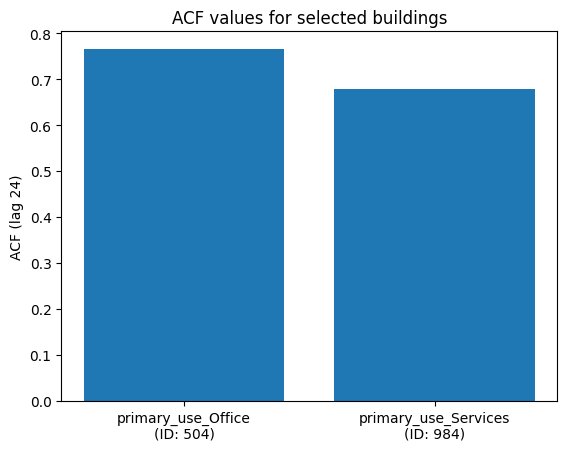

In [6]:
building_counts = {'primary_use_Office': 504, 'primary_use_Services': 984}
categories_selected = list(building_counts.keys())
ids = list(building_counts.values())

acfs = {}
for b_id in ids:
    for b_type, vals in acf24_per_type.items():
        for (building, acf_val) in vals:
            if building == b_id:
                acfs[b_id] = acf_val
                break

fig, ax = plt.subplots()
ax.bar(range(len(ids)), [acfs[b] for b in ids], tick_label=[f'{cat}\n(ID: {b})' for cat, b in zip(categories_selected, ids)], align='center')
ax.set_ylabel('ACF (lag 24)')
ax.set_title('ACF values for selected buildings')
mpld3.save_html(fig, "./top.html")
plt.show()

In [9]:
ids = list(building_counts.values())

acfs = {}
for b_id in ids:
    for b_type, vals in acf24_per_type.items():
        for (building, acf_val) in vals:
            if building == b_id:
                acfs[b_id] = acf_val
                break

print(acfs)

{504: np.float64(0.7654082089453099), 984: np.float64(0.6790648269972084)}


AttributeError: module 'mpld3' has no attribute 'write_html'

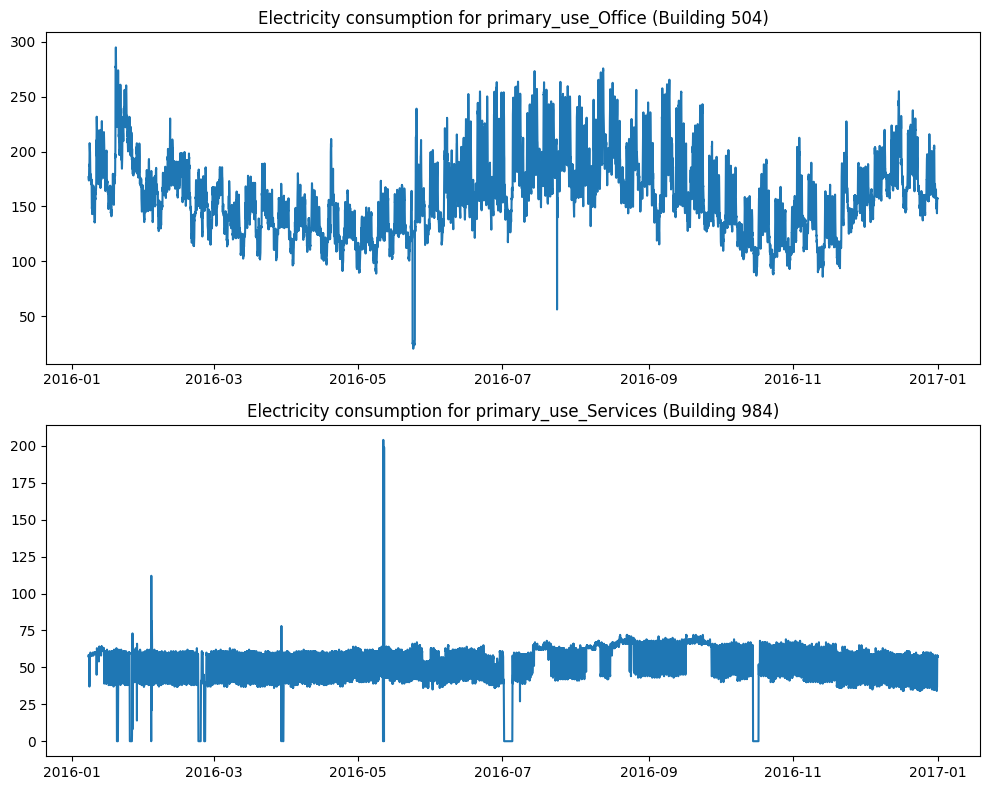

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

categories = list(building_counts.keys())
ids = list(building_counts.values())

for i, (category, b) in enumerate(zip(categories, ids)):
    s = per_building[b]['meter_reading']
    ax[i].plot(s.index, s.values)
    ax[i].set_title(f'Electricity consumption for {category} (Building {b})')

plt.tight_layout()
mpld3.write_html(fig, "plot.html")
plt.show()